---
title: "CDEaDPP 2026.2 - Trabalho Final (Python)"
subtitle: "Ciência de Dados e Estatística aplicada a Direito e Políticas Públicas"
author: "Cleuler Barbosa das Neves"
date: today
format:
  html:
    toc: true
    toc-depth: 3
    toc-title: "Sumário"
    number-sections: true
    code-fold: false
    code-tools: true
    theme: cosmo
  pdf:
    toc: true
    number-sections: true
    colorlinks: true
---


In [28]:
#| label: setup
#| include: false

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.power import TTestIndPower, GofChisquarePower
import os

# Configurações gerais
sns.set_theme(style="whitegrid", rc={"axes.titlesize": 12})
pd.set_option('display.precision', 4)
np.random.seed(2025)


# Quadro de Variáveis da Pesquisa

## Dicionário de Dados


In [29]:
#| label: tbl-dicionario
#| tbl-cap: "Dicionário de dados da pesquisa"

# Criar dicionário de dados
dicionario = pd.DataFrame({
    "Nome": [
        "id", "dias_preso", "idade_fato", "tipo_penal", "tipo_acao", "reincidencia"
    ],
    "Finalidade": [
        "Identificador único do caso",
        "Número de dias em que o réu permaneceu preso",
        "Idade do réu em anos completos na data do fato",
        "Classificação do tipo penal imputado",
        "Tipo de ação processual",
        "Se houve reincidência criminal"
    ],
    "Tipo": [
        "Identificador", "Quantitativa contínua", "Quantitativa discreta",
        "Categórica nominal", "Categórica nominal", "Categórica binária"
    ],
    "Exemplo": [
        "001, 002, 003...", "15, 30, 120...", "18, 25, 42...",
        "Furto, Roubo, Tráfico...", "Pública, Privada", "Sim, Não"
    ]
})

# Exibir tabela formatada
display(dicionario.style.set_properties(**{'text-align': 'left'}))

,Nome,Finalidade,Tipo,Exemplo
0,id,Identificador único do caso,Identificador,"001, 002, 003..."
1,dias_preso,Número de dias em que o réu permaneceu preso,Quantitativa contínua,"15, 30, 120..."
2,idade_fato,Idade do réu em anos completos na data do fato,Quantitativa discreta,"18, 25, 42..."
3,tipo_penal,Classificação do tipo penal imputado,Categórica nominal,"Furto, Roubo, Tráfico..."
4,tipo_acao,Tipo de ação processual,Categórica nominal,"Pública, Privada"
5,reincidencia,Se houve reincidência criminal,Categórica binária,"Sim, Não"



### Descrição das Variáveis

**Variáveis Quantitativas:**

-   **dias_preso**: Número de dias que o réu permaneceu preso preventivamente ou após condenação
-   **idade_fato**: Idade do réu em anos completos na data em que ocorreu o fato criminoso

**Variáveis Categóricas:**

-   **tipo_penal**: Classificação do crime (Furto, Roubo, Tráfico de Drogas, Homicídio, Outros)
-   **tipo_acao**: Natureza da ação processual (Pública ou Privada)
-   **reincidencia**: Indica se o réu é reincidente (Sim ou Não)

# Dados Simulados


In [30]:
#| label: criar-dados-simulados
#| echo: true

# Criar dados simulados para 100 observações
n = 100

dados = pd.DataFrame({
    'id': [f"{i:03d}" for i in range(1, n + 1)],
    
    # Variável quantitativa: dias preso (distribuição assimétrica)
    'dias_preso': np.round(np.random.exponential(scale=60, size=n) + np.random.uniform(0, 10, size=n)),
    
    # Variável quantitativa: idade no fato (distribuição aproximadamente normal)
    'idade_fato': np.round(np.random.normal(loc=32, scale=12, size=n)),
    
    # Variável categórica: tipo penal
    'tipo_penal': np.random.choice(
        ["Furto", "Roubo", "Tráfico", "Homicídio", "Outros"],
        size=n,
        p=[0.25, 0.20, 0.30, 0.10, 0.15]
    ),
    
    # Variável categórica: tipo de ação
    'tipo_acao': np.random.choice(["Pública", "Privada"], size=n, p=[0.90, 0.10]),
    
    # Variável categórica binária: reincidência
    'reincidencia': np.random.choice(["Sim", "Não"], size=n, p=[0.35, 0.65])
})

# Ajustar idades para valores realistas (18 a 75 anos)
dados['idade_fato'] = dados['idade_fato'].clip(18, 75)

# Visualizar primeiras observações
display(dados.head(10))

,id,dias_preso,idade_fato,tipo_penal,tipo_acao,reincidencia
0,001,12.0,38.0,Furto,Pública,Não
1,002,134.0,35.0,Furto,Pública,Não
2,003,171.0,18.0,Homicídio,Pública,Sim
3,004,37.0,31.0,Tráfico,Pública,Não
4,005,30.0,33.0,Homicídio,Pública,Não
5,006,28.0,33.0,Furto,Pública,Sim
6,007,74.0,39.0,Furto,Pública,Sim
7,008,42.0,22.0,Tráfico,Pública,Não
8,009,201.0,26.0,Roubo,Pública,Não
9,010,100.0,23.0,Outros,Pública,Sim



## Salvando os Dados


In [31]:
#| label: salvar-dados
#| echo: true

# Criar diretório se não existir
os.makedirs("out", exist_ok=True)

# Salvar em CSV e Pickle
dados.to_csv("out/dados_pesquisa.csv", index=False)
dados.to_pickle("out/dados_pesquisa.pkl")

print("Dados salvos com sucesso em:")
print("  - out/dados_pesquisa.csv")
print("  - out/dados_pesquisa.pkl")

Dados salvos com sucesso em:
  - out/dados_pesquisa.csv
  - out/dados_pesquisa.pkl



# Análise Exploratória de Dados (AED) - Univariada

## Análise da Variável: Dias Preso


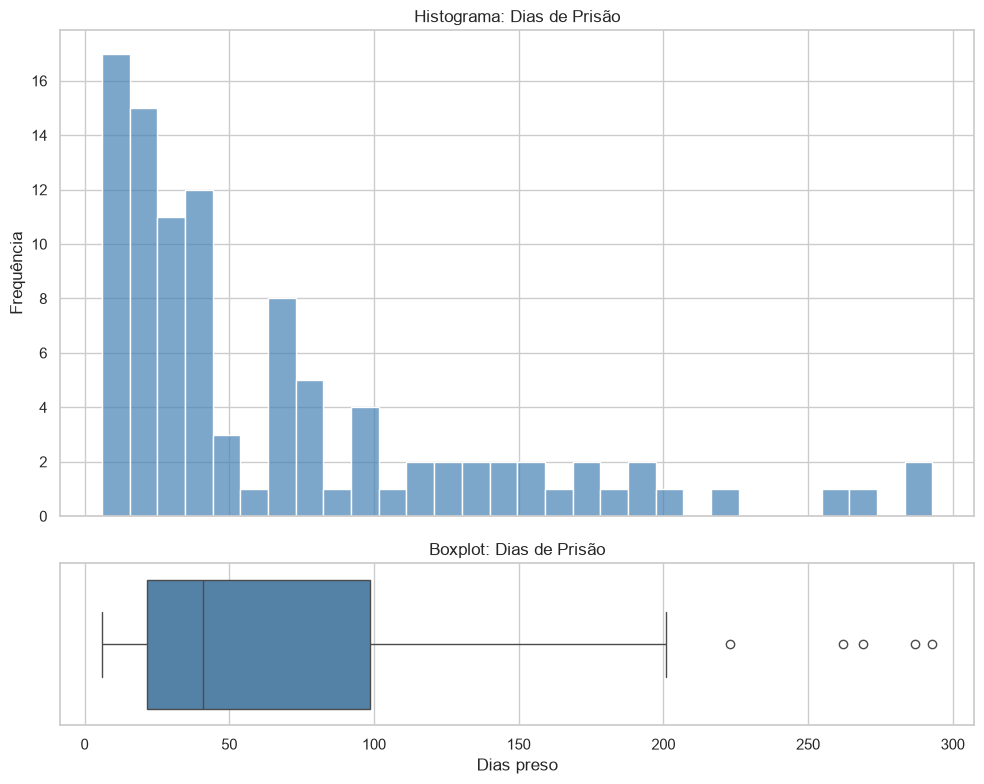

In [32]:
#| label: fig-dias-preso
#| fig-cap: "Distribuição de frequência dos dias de prisão"
#| fig-width: 10
#| fig-height: 6

# Criar gráficos
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

sns.histplot(data=dados, x="dias_preso", bins=30, color="steelblue", alpha=0.7, ax=axes[0])
axes[0].set_title("Histograma: Dias de Prisão")
axes[0].set_ylabel("Frequência")
axes[0].set_xlabel("")

sns.boxplot(data=dados, x="dias_preso", color="steelblue", ax=axes[1])
axes[1].set_title("Boxplot: Dias de Prisão")
axes[1].set_xlabel("Dias preso")

plt.tight_layout()
plt.show()


### Medidas Resumo: Dias Preso


In [33]:
#| label: resumo-dias-preso

# Estatísticas descritivas
resumo_dias = pd.DataFrame({
    'N': [len(dados)],
    'Média': [dados['dias_preso'].mean()],
    'Mediana': [dados['dias_preso'].median()],
    'Desvio Padrão': [dados['dias_preso'].std()],
    'Mínimo': [dados['dias_preso'].min()],
    'Q1 (25%)': [dados['dias_preso'].quantile(0.25)],
    'Q3 (75%)': [dados['dias_preso'].quantile(0.75)],
    'Máximo': [dados['dias_preso'].max()],
    'Assimetria': [stats.skew(dados['dias_preso'])],
    'Curtose': [stats.kurtosis(dados['dias_preso'])]
}).T
resumo_dias.columns = ['Valor']

display(resumo_dias)

,Valor
N,100.0000
Média,69.8900
Mediana,41.0000
Desvio Padrão,68.4619
Mínimo,6.0000
Q1 (25%),21.7500
Q3 (75%),98.5000
Máximo,293.0000
Assimetria,1.4902
Curtose,1.6333



**Interpretação:**

\[Descrever os padrões observados na distribuição de dias preso, identificar outliers se houver, comentar sobre assimetria e dispersão dos dados\]

## Análise da Variável: Idade no Fato


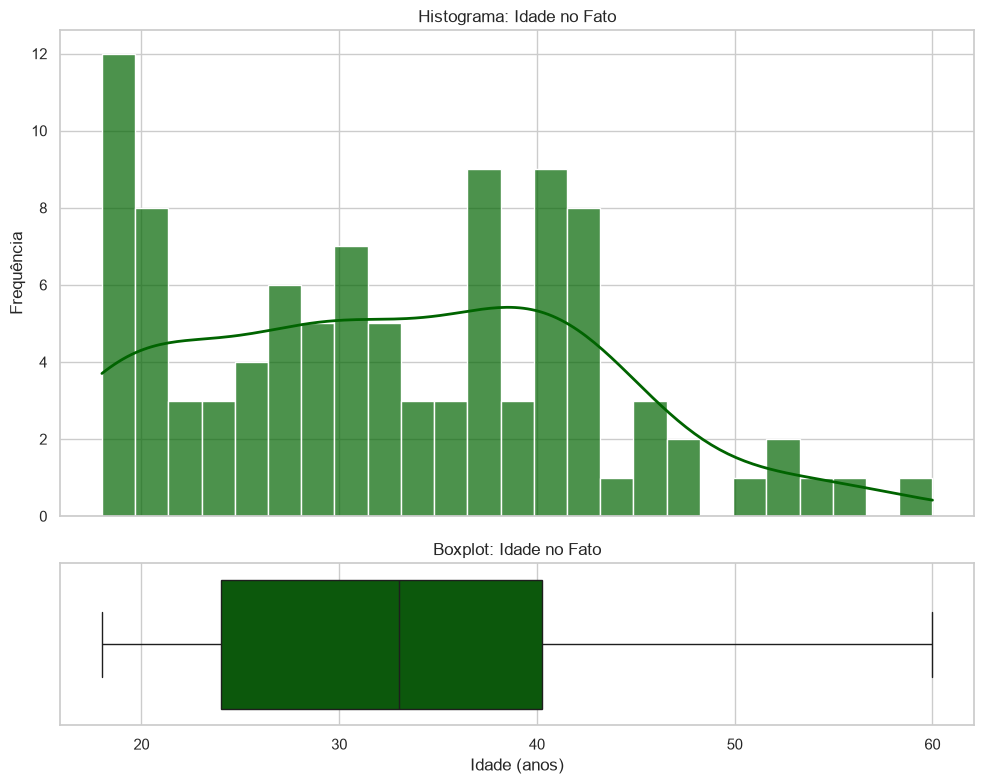

In [34]:
#| label: fig-idade-fato
#| fig-cap: "Distribuição de frequência da idade no momento do fato"
#| fig-width: 10
#| fig-height: 6

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

sns.histplot(data=dados, x="idade_fato", bins=25, color="darkgreen", alpha=0.7, kde=True, line_kws={"color":"red", "lw":2}, ax=axes[0])
axes[0].set_title("Histograma: Idade no Fato")
axes[0].set_ylabel("Frequência")
axes[0].set_xlabel("")

sns.boxplot(data=dados, x="idade_fato", color="darkgreen", ax=axes[1])
axes[1].set_title("Boxplot: Idade no Fato")
axes[1].set_xlabel("Idade (anos)")

plt.tight_layout()
plt.show()


### Medidas Resumo: Idade no Fato


In [35]:
#| label: resumo-idade

resumo_idade = pd.DataFrame({
    'N': [len(dados)],
    'Média': [dados['idade_fato'].mean()],
    'Mediana': [dados['idade_fato'].median()],
    'Desvio Padrão': [dados['idade_fato'].std()],
    'Mínimo': [dados['idade_fato'].min()],
    'Q1 (25%)': [dados['idade_fato'].quantile(0.25)],
    'Q3 (75%)': [dados['idade_fato'].quantile(0.75)],
    'Máximo': [dados['idade_fato'].max()]
}).T
resumo_idade.columns = ['Valor']

display(resumo_idade)

,Valor
N,100.0000
Média,32.8100
Mediana,33.0000
Desvio Padrão,10.2462
Mínimo,18.0000
Q1 (25%),24.0000
Q3 (75%),40.2500
Máximo,60.0000



**Interpretação:**

\[Descrever os padrões observados na distribuição de idade, comentar sobre normalidade, identificar outliers se houver\]

## Análise da Variável: Tipo Penal


C:\Users\Cleuler\AppData\Local\Temp\ipykernel_31348\1564029867.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=freq_tipo, x='tipo_penal', y='n', palette='viridis')


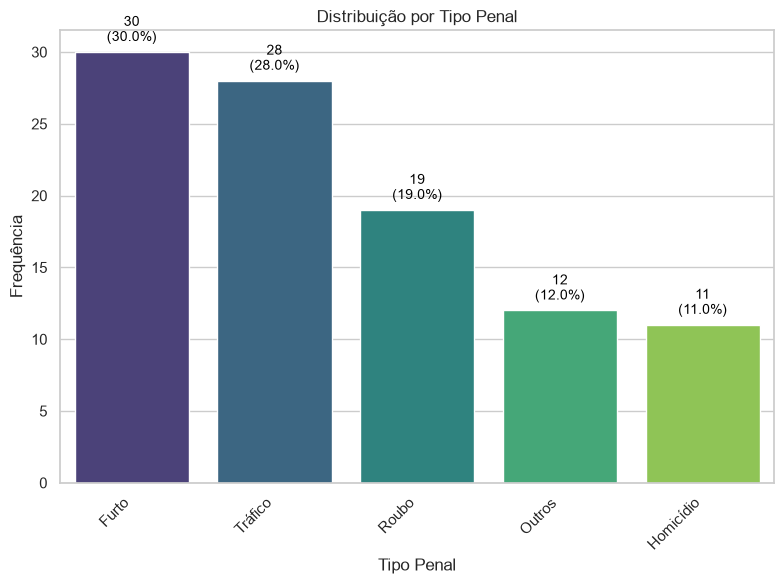

In [36]:
#| label: fig-tipo-penal
#| fig-cap: "Distribuição de frequência do tipo penal"
#| fig-width: 8
#| fig-height: 6

# Tabela de frequências
freq_tipo = dados['tipo_penal'].value_counts().reset_index()
freq_tipo.columns = ['tipo_penal', 'n']
freq_tipo['Percentual'] = (freq_tipo['n'] / freq_tipo['n'].sum()) * 100
freq_tipo['Percentual Acumulado'] = freq_tipo['Percentual'].cumsum()

# Gráfico de barras
plt.figure(figsize=(8, 6))
ax = sns.barplot(data=freq_tipo, x='tipo_penal', y='n', palette='viridis')

for p, perc in zip(ax.patches, freq_tipo['Percentual']):
    ax.annotate(f"{int(p.get_height())}\n({perc:.1f}%)",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.title("Distribuição por Tipo Penal")
plt.xlabel("Tipo Penal")
plt.ylabel("Frequência")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### Tabela de Frequências: Tipo Penal


In [37]:
#| label: tbl-freq-tipo-penal
#| tbl-cap: "Frequências do tipo penal"

freq_tipo_show = freq_tipo.copy()
freq_tipo_show.columns = ["Tipo Penal", "Frequência", "Percentual (%)", "Acumulado (%)"]
display(freq_tipo_show.round(2))

,Tipo Penal,Frequência,Percentual (%),Acumulado (%)
0,Furto,30,30.0,30.0
1,Tráfico,28,28.0,58.0
2,Roubo,19,19.0,77.0
3,Outros,12,12.0,89.0
4,Homicídio,11,11.0,100.0



**Interpretação:**

\[Descrever os padrões observados na distribuição do tipo penal, identificar categorias mais e menos frequentes\]

## Análise das Outras Variáveis Categóricas


C:\Users\Cleuler\AppData\Local\Temp\ipykernel_31348\3568610963.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=dados, x='tipo_acao', palette='Set2', ax=axes[0])
C:\Users\Cleuler\AppData\Local\Temp\ipykernel_31348\3568610963.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=dados, x='reincidencia', palette='Set1', ax=axes[1])


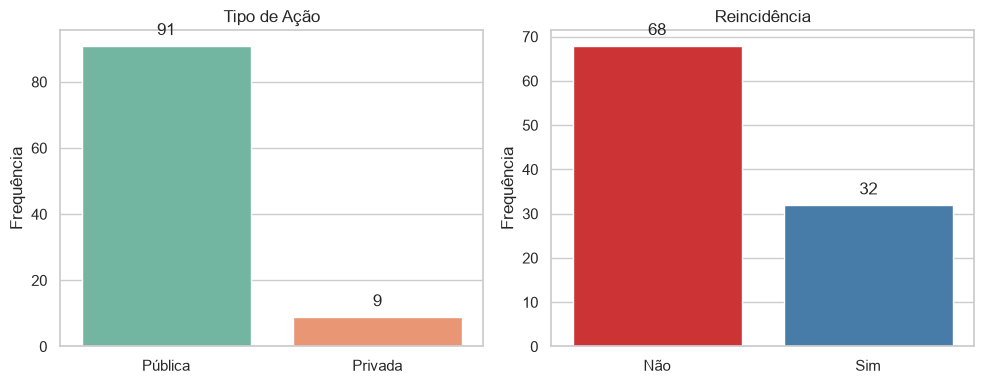

In [38]:
#| label: fig-categoricas
#| fig-cap: "Distribuição das variáveis categóricas"
#| fig-width: 10
#| fig-height: 4

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=dados, x='tipo_acao', palette='Set2', ax=axes[0])
axes[0].set_title("Tipo de Ação")
axes[0].set_xlabel("")
axes[0].set_ylabel("Frequência")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

sns.countplot(data=dados, x='reincidencia', palette='Set1', ax=axes[1])
axes[1].set_title("Reincidência")
axes[1].set_xlabel("")
axes[1].set_ylabel("Frequência")
for p in axes[1].patches:
    axes[1].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()


**Interpretação:**

\[Descrever os padrões observados nas variáveis tipo_acao e reincidencia\]

# Análise Exploratória de Dados (AED) - Bivariada

## Duas Variáveis Quantitativas: Dias Preso × Idade no Fato


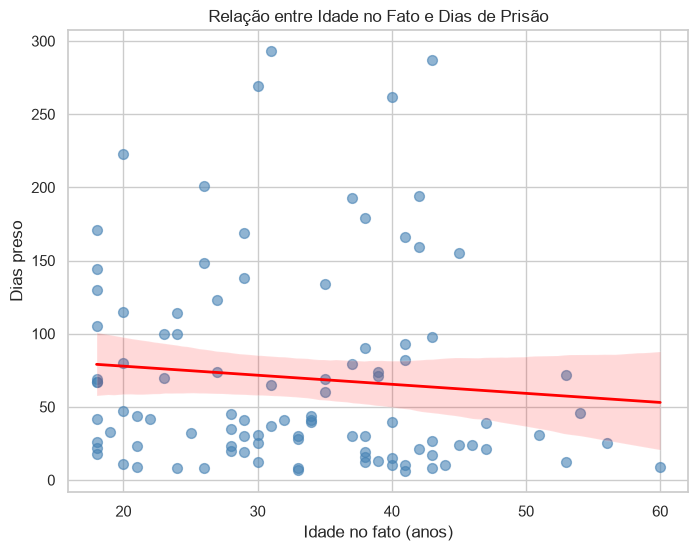

In [39]:
#| label: fig-scatter-dias-idade
#| fig-cap: "Relação entre dias de prisão e idade no fato"
#| fig-width: 8
#| fig-height: 6

plt.figure(figsize=(8, 6))
sns.regplot(data=dados, x="idade_fato", y="dias_preso", 
            scatter_kws={"alpha": 0.6, "color": "steelblue", "s": 50}, 
            line_kws={"color": "red", "lw": 2})
plt.title("Relação entre Idade no Fato e Dias de Prisão")
plt.xlabel("Idade no fato (anos)")
plt.ylabel("Dias preso")
plt.show()


### Modelo de Regressão Linear


In [40]:
#| label: modelo-regressao

# Ajustar modelo de regressão linear
X = sm.add_constant(dados['idade_fato'])
y = dados['dias_preso']
modelo_lm = sm.OLS(y, X).fit()

# Resumo do modelo
print(modelo_lm.summary())

# Coeficientes
coef_b0 = modelo_lm.params['const']
coef_b1 = modelo_lm.params['idade_fato']

                            OLS Regression Results                            
Dep. Variable:             dias_preso   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                 -0.002
Method:                 Least Squares   F-statistic:                    0.8504
Date:                Sat, 31 Oct 2026   Prob (F-statistic):              0.359
Time:                        23:21:55   Log-Likelihood:                -563.59
No. Observations:                 100   AIC:                             1131.
Df Residuals:                      98   BIC:                             1136.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         90.2233     23.090      3.908      0.0


**Equação da reta:**

$$\hat{y} = \beta_0 + \beta_1 \cdot x$$
*(Substitua os valores com os resultados acima)*

### Medidas de Correlação


In [41]:
#| label: correlacao

# Correlação de Pearson
cor_pearson, p_value = stats.pearsonr(dados['idade_fato'], dados['dias_preso'])

# Teste de correlação e IC 95% (usando Fisher's Z)
z = np.arctanh(cor_pearson)
se = 1 / np.sqrt(len(dados) - 3)
ci_low = np.tanh(z - 1.96 * se)
ci_high = np.tanh(z + 1.96 * se)

print(f"Correlação de Pearson: {cor_pearson:.4f}")
print(f"Valor-p: {p_value:.4e}")
print(f"IC 95%: [{ci_low:.4f}, {ci_high:.4f}]")

Correlação de Pearson: -0.0928
Valor-p: 3.5871e-01
IC 95%: [-0.2840, 0.1056]



**Interpretação:**

\[Interpretar a força e direção da correlação, significância estatística, e a qualidade do ajuste do modelo linear\]

## Duas Variáveis Categóricas: Tipo Penal × Reincidência


In [42]:
#| label: tbl-contingencia
#| tbl-cap: "Tabela de contingência: Tipo Penal × Reincidência"

# Criar tabela de contingência com totais marginais
tabela_cont = pd.crosstab(dados['tipo_penal'], dados['reincidencia'], margins=True, margins_name="Total")

display(tabela_cont)

reincidencia,Não,Sim,Total
tipo_penal,,,
Furto,23,7,30
Homicídio,7,4,11
Outros,8,4,12
Roubo,13,6,19
Tráfico,17,11,28
Total,68,32,100



### Percentuais por Linha


In [43]:
#| label: tbl-percentuais-linha

# Percentuais por linha
tabela_prop_linha = pd.crosstab(dados['tipo_penal'], dados['reincidencia'], normalize='index') * 100

display(tabela_prop_linha.round(2))

reincidencia,Não,Sim
tipo_penal,,
Furto,76.67,23.33
Homicídio,63.64,36.36
Outros,66.67,33.33
Roubo,68.42,31.58
Tráfico,60.71,39.29



### Gráfico de Barras Agrupadas


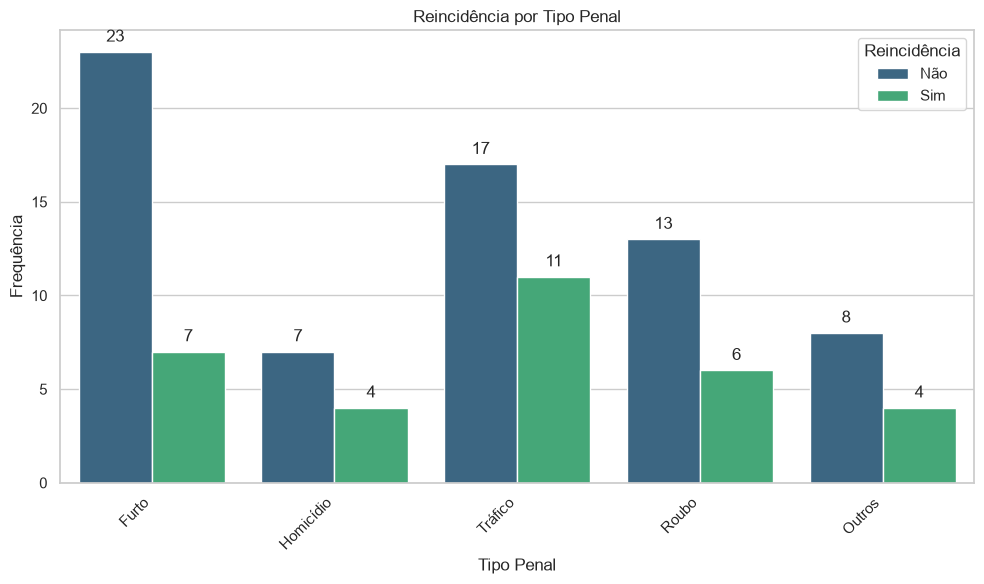

In [44]:
#| label: fig-barras-agrupadas
#| fig-cap: "Distribuição de reincidência por tipo penal"
#| fig-width: 10
#| fig-height: 6

plt.figure(figsize=(10, 6))
ax = sns.countplot(data=dados, x="tipo_penal", hue="reincidencia", palette="viridis")

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(int(p.get_height()), 
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')

plt.title("Reincidência por Tipo Penal")
plt.xlabel("Tipo Penal")
plt.ylabel("Frequência")
plt.legend(title="Reincidência")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Interpretação:**

\[Descrever os padrões de associação entre tipo penal e reincidência\]

## Uma Variável Quantitativa e Uma Categórica: Dias Preso × Reincidência


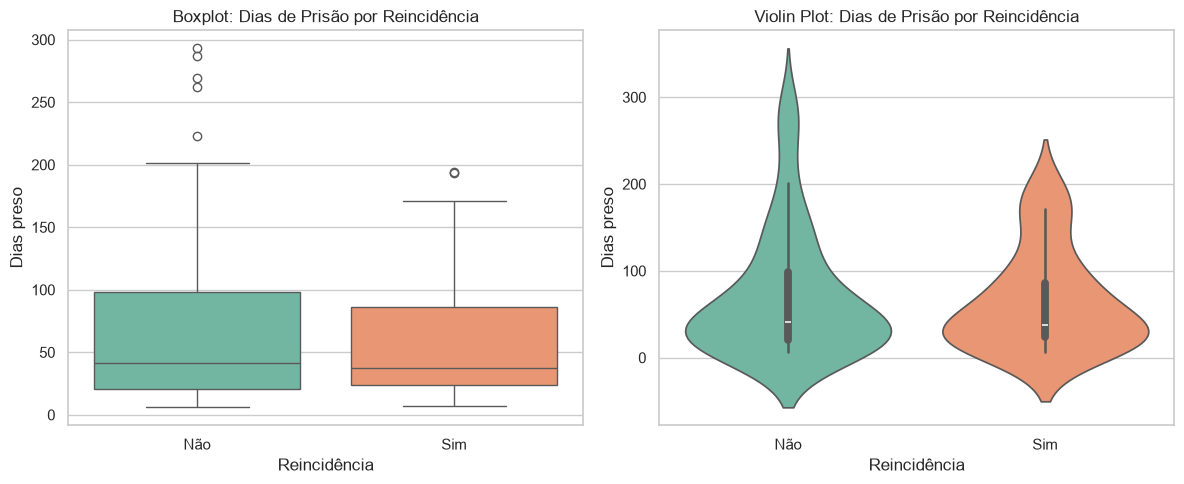

In [45]:
#| label: fig-boxplot-dias-reincidencia
#| fig-cap: "Comparação de dias de prisão por reincidência"
#| fig-width: 10
#| fig-height: 6

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=dados, x="reincidencia", y="dias_preso", hue="reincidencia", legend=False, palette="Set2", ax=axes[0])
axes[0].set_title("Boxplot: Dias de Prisão por Reincidência")
axes[0].set_xlabel("Reincidência")
axes[0].set_ylabel("Dias preso")

sns.violinplot(data=dados, x="reincidencia", y="dias_preso", hue="reincidencia", legend=False, palette="Set2", inner="box", ax=axes[1])
axes[1].set_title("Violin Plot: Dias de Prisão por Reincidência")
axes[1].set_xlabel("Reincidência")
axes[1].set_ylabel("Dias preso")

plt.tight_layout()
plt.show()


### Medidas Resumo por Grupo


In [46]:
#| label: tbl-resumo-grupo

resumo_grupos = dados.groupby('reincidencia')['dias_preso'].agg(
    N='count',
    Média='mean',
    Mediana='median',
    Desvio_Padrão='std',
    Mínimo='min',
    Máximo='max'
).reset_index()

display(resumo_grupos.round(2))

,reincidencia,N,Média,Mediana,Desvio_Padrão,Mínimo,Máximo
0,Não,68,72.00,41.5,73.45,6.0,293.0
1,Sim,32,65.41,37.5,57.26,7.0,194.0



**Interpretação:**

\[Comparar as distribuições de dias de prisão entre reincidentes e não-reincidentes, identificar diferenças e valores influentes\]

# Reflexão sobre Variáveis Ocultas ou de Confundimento

**Possíveis variáveis de confundimento:**

1.  **Condição Socioeconômica**: Pode influenciar tanto o tipo de crime quanto o tempo de prisão, além de afetar o acesso à defesa adequada.

2.  **Região/Comarca**: Diferentes comarcas podem ter padrões distintos de aplicação de penas e concessão de liberdade.

3.  **Qualidade da Defesa**: Réus com advogados particulares vs. defensoria pública podem ter resultados diferentes.

4.  **Gravidade do Delito**: Dentro de cada tipo penal, há variações de gravidade que não foram capturadas.

5.  **Antecedentes Criminais**: Além da reincidência binária, o número e tipo de antecedentes podem influenciar.

6.  **Tempo até o Julgamento**: Pode afetar o tempo total de prisão independentemente da sentença.

\[Adicionar mais reflexões específicas ao seu contexto de pesquisa\]

# Testes de Significância contra Hipótese Nula

## Teste 1: Normalidade da Distribuição de Dias Preso

### Hipóteses

-   $H_0$: A distribuição de dias preso segue uma distribuição normal
-   $H_a$: A distribuição de dias preso não segue uma distribuição normal

**Tipo de teste:** Bilateral  
**Nível de significância:** $\alpha = 0.05$


In [47]:
#| label: teste-normalidade

# Teste de Shapiro-Wilk
stat_shapiro, p_shapiro = stats.shapiro(dados['dias_preso'])

print("Teste de Shapiro-Wilk")
print(f"Estatística W: {stat_shapiro:.4f}")
print(f"Valor-p: {p_shapiro:.4e}")

print("\nConclusão:")
if p_shapiro < 0.05:
    print(" Rejeita-se H0. Evidências de não-normalidade.")
else:
    print(" Não se rejeita H0. Dados consistentes com normalidade.")

Teste de Shapiro-Wilk
Estatística W: 0.8127
Valor-p: 6.2095e-10

Conclusão:
 Rejeita-se H0. Evidências de não-normalidade.



**Interpretação:**

\[Interpretar o resultado no contexto estatístico e no contexto da pesquisa\]

## Teste 2: Correlação entre Idade no Fato e Dias Preso

### Hipóteses

-   $H_0$: $
\rho = 0$ (não há correlação linear entre idade no fato e dias preso)
-   $H_a$: $
\rho 
\neq 0$ (há correlação linear entre as variáveis)

**Tipo de teste:** Bilateral  
**Nível de significância:** $\alpha = 0.05$


In [48]:
#| label: teste-correlacao

# Teste de correlação (já realizado anteriormente)
print(f"Correlação de Pearson: {cor_pearson:.4f}, p-valor: {p_value:.4e}")

print("\nConclusão:")
if p_value < 0.05:
    print(" Rejeita-se H0. Há evidência de correlação significativa.")
else:
    print(" Não se rejeita H0. Não há evidência de correlação significativa.")

Correlação de Pearson: -0.0928, p-valor: 3.5871e-01

Conclusão:
 Não se rejeita H0. Não há evidência de correlação significativa.



**Interpretação:**

\[Interpretar o resultado no contexto estatístico e no contexto da pesquisa\]

## Teste 3: Independência entre Tipo Penal e Reincidência

### Hipóteses

-   $H_0$: Tipo penal e reincidência são independentes
-   $H_a$: Existe associação entre tipo penal e reincidência

**Tipo de teste:** Bilateral  
**Nível de significância:** $\alpha = 0.05$


In [49]:
#| label: teste-qui-quadrado

# Teste qui-quadrado de independência
tabela_chi2 = pd.crosstab(dados['tipo_penal'], dados['reincidencia'])
chi2, p_val_chi2, dof, expected = stats.chi2_contingency(tabela_chi2)

print("Teste Qui-Quadrado de Independência")
print(f"X² = {chi2:.4f}")
print(f"gl = {dof}")
print(f"Valor-p: {p_val_chi2:.4e}")

print("\nValores Esperados:")
print(pd.DataFrame(expected, index=tabela_chi2.index, columns=tabela_chi2.columns).round(2))

print("\nConclusão:")
if p_val_chi2 < 0.05:
    print(" Rejeita-se H0. Há evidência de associação significativa.")
else:
    print(" Não se rejeita H0. Não há evidência de associação significativa.")

Teste Qui-Quadrado de Independência
X² = 1.8262
gl = 4
Valor-p: 7.6769e-01

Valores Esperados:
reincidencia    Não   Sim
tipo_penal               
Furto         20.40  9.60
Homicídio      7.48  3.52
Outros         8.16  3.84
Roubo         12.92  6.08
Tráfico       19.04  8.96

Conclusão:
 Não se rejeita H0. Não há evidência de associação significativa.



**Interpretação:**

\[Interpretar o resultado no contexto estatístico e no contexto da pesquisa\]

## Teste 4: Comparação de Médias - Dias Preso por Reincidência

### Hipóteses

-   $H_0$: $\mu_{Sim} = \mu_{Não}$ (médias iguais de dias preso para reincidentes e não-reincidentes)
-   $H_a$: $\mu_{Sim}
\neq \mu_{Não}$ (médias diferentes)

**Tipo de teste:** Bilateral  
**Nível de significância:** $\alpha = 0.05$


In [50]:
#| label: teste-t

# Teste t para duas amostras independentes
grupo_sim = dados[dados['reincidencia'] == 'Sim']['dias_preso']
grupo_nao = dados[dados['reincidencia'] == 'Não']['dias_preso']

t_stat, p_val_t = stats.ttest_ind(grupo_sim, grupo_nao, equal_var=True)
df_t = len(grupo_sim) + len(grupo_nao) - 2

# IC 95% para diferença
diff_mean = grupo_sim.mean() - grupo_nao.mean()
se_diff = np.sqrt(grupo_sim.var(ddof=1)/len(grupo_sim) + grupo_nao.var(ddof=1)/len(grupo_nao))
ci_low_t = diff_mean - 1.96 * se_diff
ci_high_t = diff_mean + 1.96 * se_diff

print("Teste t de Student para Duas Amostras")
print(f"t = {t_stat:.4f}")
print(f"gl = {df_t}")
print(f"Valor-p: {p_val_t:.4e}")
print(f"IC 95% para diferença: {ci_low_t:.2f} a {ci_high_t:.2f}")

print("\nConclusão:")
if p_val_t < 0.05:
    print(" Rejeita-se H0. Há evidência de diferença significativa nas médias.")
else:
    print(" Não se rejeita H0. Não há evidência de diferença significativa nas médias.")

Teste t de Student para Duas Amostras
t = -0.4475
gl = 98
Valor-p: 6.5553e-01
IC 95% para diferença: -33.02 a 19.83

Conclusão:
 Não se rejeita H0. Não há evidência de diferença significativa nas médias.



**Interpretação:**

\[Interpretar o resultado no contexto estatístico e no contexto da pesquisa\]

# Cálculo do Tamanho da Amostra

## Para Variável Quantitativa (Dias Preso)

Usando o teste t para duas médias independentes.


In [51]:
#| label: calculo-amostra-quantitativa

# Parâmetros
alpha = 0.05
poder_desejado = 0.85

# Calcular tamanho do efeito observado (d de Cohen)
media_sim = grupo_sim.mean()
media_nao = grupo_nao.mean()
dp_pooled = np.sqrt(((len(grupo_sim)-1)*grupo_sim.var(ddof=1) + (len(grupo_nao)-1)*grupo_nao.var(ddof=1)) / (len(dados)-2))

d_cohen = abs(media_sim - media_nao) / dp_pooled
print(f"Tamanho do efeito observado (d de Cohen): {d_cohen:.3f}\n")

# Calcular tamanho de amostra para diferentes tamanhos de efeito
tamanhos_efeito = [0.2, 0.5, 0.8, d_cohen]
poderes = [0.80, 0.85, 0.90, 0.95]

resultados_quant = []
analysis_t = TTestIndPower()

for p in poderes:
    for d in tamanhos_efeito:
        n_per_group = np.ceil(analysis_t.solve_power(effect_size=d, power=p, alpha=alpha, ratio=1.0, alternative='two-sided'))
        resultados_quant.append({
            'Tamanho Efeito (d)': d,
            'Poder (1-β)': p,
            'N por Grupo': int(n_per_group),
            'N Total': int(n_per_group * 2)
        })

df_quant = pd.DataFrame(resultados_quant)
display(df_quant.round(3))

Tamanho do efeito observado (d de Cohen): 0.096



,Tamanho Efeito (d),Poder (1-β),N por Grupo,N Total
0,0.200,0.80,394,788
1,0.500,0.80,64,128
2,0.800,0.80,26,52
3,0.096,0.80,1708,3416
4,0.200,0.85,450,900
5,0.500,0.85,73,146
6,0.800,0.85,30,60
7,0.096,0.85,1953,3906
8,0.200,0.90,527,1054
9,0.500,0.90,86,172



## Para Variável Categórica (Reincidência)

Usando o teste qui-quadrado para proporções.


In [52]:
#| label: calculo-amostra-categorica

# Calcular tamanho do efeito observado (w de Cohen)
w_cohen = np.sqrt(chi2 / len(dados))
print(f"Tamanho do efeito observado (w de Cohen): {w_cohen:.3f}\n")

# Calcular tamanho de amostra para diferentes tamanhos de efeito
# w: 0.1 (pequeno), 0.3 (médio), 0.5 (grande)
tamanhos_efeito_w = [0.1, 0.3, 0.5, w_cohen]
df_chi = (5 - 1) * (2 - 1) # (linhas - 1) * (colunas - 1)

resultados_cat = []
analysis_chi = GofChisquarePower()

for p in poderes:
    for w in tamanhos_efeito_w:
        n_total = np.ceil(analysis_chi.solve_power(effect_size=w, nobs=None, alpha=alpha, power=p, n_bins=df_chi+1))
        resultados_cat.append({
            'Tamanho Efeito (w)': w,
            'Poder (1-β)': p,
            'N Total': int(n_total)
        })

df_cat = pd.DataFrame(resultados_cat)
display(df_cat.round(3))

Tamanho do efeito observado (w de Cohen): 0.135



,Tamanho Efeito (w),Poder (1-β),N Total
0,0.100,0.80,1194
1,0.300,0.80,133
2,0.500,0.80,48
3,0.135,0.80,654
4,0.100,0.85,1343
5,0.300,0.85,150
6,0.500,0.85,54
7,0.135,0.85,735
8,0.100,0.90,1541
9,0.300,0.90,172



## Recomendação Final


In [53]:
#| label: recomendacao-amostra

# Considerar o maior N necessário entre os dois testes
try:
    n_recomendado_quant = df_quant[(df_quant['Poder (1-β)'] == 0.85) & (np.isclose(df_quant['Tamanho Efeito (d)'], 0.5))]['N Total'].values[0]
except IndexError:
    n_recomendado_quant = 0
    
try:
    n_recomendado_cat = df_cat[(df_cat['Poder (1-β)'] == 0.85) & (np.isclose(df_cat['Tamanho Efeito (w)'], 0.3))]['N Total'].values[0]
except IndexError:
    n_recomendado_cat = 0

n_final = max(n_recomendado_quant, n_recomendado_cat)

print("RECOMENDAÇÃO DE TAMANHO AMOSTRAL")
print("=================================\n")
print("Considerando:")
print("  - Erro Tipo I (α) = 5%")
print("  - Poder mínimo (1-β) = 85%")
print("  - Tamanho do efeito médio\n")
print(f"Tamanho de amostra recomendado: {int(n_final)} observações\n")
print("Para maior segurança, considerar adicionar 10-15% para compensar")
print("possíveis perdas e não-respostas.")
print(f"Tamanho final sugerido: {int(np.ceil(n_final * 1.15))} observações")

RECOMENDAÇÃO DE TAMANHO AMOSTRAL

Considerando:
  - Erro Tipo I (α) = 5%
  - Poder mínimo (1-β) = 85%
  - Tamanho do efeito médio

Tamanho de amostra recomendado: 150 observações

Para maior segurança, considerar adicionar 10-15% para compensar
possíveis perdas e não-respostas.
Tamanho final sugerido: 173 observações



# Conclusão

\[Escrever conclusão abrangente que inclua:\]

1.  Principais achados da análise exploratória univariada
2.  Principais achados da análise exploratória bivariada
3.  Resultados dos testes de hipótese realizados
4.  Implicações dos resultados para a pesquisa
5.  Limitações do estudo atual
6.  Recomendações para a coleta de dados definitiva
7.  Próximos passos na pesquisa

# Sugestões para Melhoria da Disciplina CDEaDPP

## Aspectos Positivos

\[Listar aspectos que funcionaram bem\]

## Sugestões de Melhoria

\[Listar sugestões construtivas para melhorar a disciplina, como:\]

1.  Conteúdo programático
2.  Metodologia de ensino
3.  Atividades práticas
4.  Materiais didáticos
5.  Avaliações
6.  Recursos computacionais
7.  Outras sugestões

# Referências Bibliográficas {.unnumbered}

BUSSAB, W. O.; MORETTIN, P. A. **Estatística básica**. 9. ed. São Paulo: Saraiva, 2017.

COHEN, J. **Statistical power analysis for the behavioral sciences**. 2nd ed. Hillsdale: Lawrence Erlbaum Associates, 1988.

FIELD, A.; MILES, J.; FIELD, Z. **Descobrindo a estatística usando R**. Porto Alegre: Bookman, 2012.

MAGALHÃES, M. N.; LIMA, A. C. P. **Noções de probabilidade e estatística**. 7. ed. São Paulo: EDUSP, 2015.

MOORE, D. S.; NOTZ, W. I.; FLIGNER, M. A. **A Estatística Básica e sua prática**. 9. ed. Rio de Janeiro: LTC, 2023.

NAVARRO, D. J.; FOXCROFT, D. R. **Learning statistics with R: a tutorial for psychology students and other beginners**. Adelaide: University of Adelaide, 2019. Disponível em: https://learningstatisticswithr.com/. Acesso em: 12 dez. 2025.

NELDER, J. A.; MCCULLAGH, P. **Generalized Linear Models**. 2nd ed. London: Chapman and Hall, 1989.

POLDRACK, R. A. **Statistical thinking for the 21st century**. 2022. Disponível em: https://statsthinking21.github.io/statsthinking21-core-site/. Acesso em: 12 dez. 2025.

R CORE TEAM. **R: A language and environment for statistical computing**. Vienna: R Foundation for Statistical Computing, 2025. Disponível em: https://www.R-project.org/. Acesso em: 12 dez. 2025.

SHAPIRO, S. S.; WILK, M. B. An analysis of variance test for normality (complete samples). **Biometrika**, v. 52, n. 3/4, p. 591-611, 1965.

STUDENT. The probable error of a mean. **Biometrika**, v. 6, n. 1, p. 1-25, 1908.

TABACHNICK, B. G.; FIDELL, L. S. **Using multivariate statistics**. 7th ed. New York: Pearson, 2019.

WICKHAM, H. et al. **Welcome to the tidyverse**. Journal of Open Source Software, v. 4, n. 43, p. 1686, 2019. DOI: 10.21105/joss.01686.

WICKHAM, H.; GROLEMUND, G. **R for data science: import, tidy, transform, visualize, and model data**. 2nd ed. Sebastopol: O'Reilly Media, 2023.

::: callout-note
## Nota sobre as Referências

As referências acima incluem as principais obras e pacotes utilizados nesta análise. Adicione outras referências específicas citadas no seu trabalho, mantendo a formatação ABNT (NBR 6023:2018).
:::

------------------------------------------------------------------------

**Data de conclusão:** 19/11/2026 (01 ao 07) e 26/11/2026 (08 ao 15 da chamada)
